# 04. Metrics to track (Task 4)

**Question this notebook answers.** Q2 from `01_clean.ipynb`: how reliable are the airlines, airports, hours and months, and how do we watch that over time? We define five numbers the agency can track every month, compute them by month, by airline and by airport group, flag the unusual months, and try the bonus forecast.

This notebook describes the **whole year**, because the metrics are reliability reports, not model inputs. Nothing here is used to choose a model.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from utils import *

set_seed()
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
fl = pd.read_parquet(PROC / "flights_clean.parquet")
we = pd.read_parquet(PROC / "weather_clean.parquet")
al = pd.read_parquet(PROC / "airlines_clean.parquet")
gr = pd.read_parquet(PROC / "groups_airport.parquet")
assert len(fl) == 435_352
print(f"{len(fl):,} flights loaded")

435,352 flights loaded


## 1. The five metrics, defined exactly

"**Departed**" means `dep_time` is not missing. "**Scheduled**" means every row of the flights file (departed or cancelled). "**Month**" is the scheduled month (`month` column). Rates are in percent. `dep_delay` is in minutes; a flight that leaves early has a negative delay.

| ID | Name | Formula (the denominator is spelled out) | Why the business cares | Up is |
| --- | --- | --- | --- | --- |
| M1 | On-time rate | number of **departed** flights with `dep_delay` ≤ 15, divided by the number of **departed** flights | Share of clients who leave on time | good |
| M2 | Average departure delay | mean of `dep_delay` over **departed** flights, in minutes (early flights count as negative) | How long clients wait on average | bad |
| M3 | Cancellation rate | number of flights with missing `dep_time`, divided by **all scheduled** flights | Clients who must be rebooked | bad |
| M4 | Share of flights more than 1 hour late | number of **departed** flights with `dep_delay` > 60, divided by the number of **departed** flights | Missed connections and complaints; the tail the mean hides | bad |
| M5 | Late-or-cancelled rate | number of flights with `dep_delay` > 15 **or** missing `dep_time`, divided by **all scheduled** flights | The exact target of prediction 1: the number the warning system tries to reduce | bad |

Two things to keep in mind. M1 and M5 look alike but have different denominators: a cancelled flight is missing from M1 (so M1 can look good in a month full of cancellations) and counted as a failure in M5. Arrival-based punctuality is **not** used: arrival times are in the destination's local time and the agency warns about departures.

In [2]:
def metrics(d):
    """The five metrics for any group of flights. Returns one row of numbers."""
    dep = d[d.dep_time.notna()]
    delay = dep.dep_delay.astype(float)
    return pd.Series({"flights": len(d),
                      "M1_on_time_%": 100 * (delay <= 15).mean(),
                      "M2_avg_delay_min": delay.mean(),
                      "M3_cancel_%": 100 * d.dep_time.isna().mean(),
                      "M4_over_60min_%": 100 * (delay > 60).mean(),
                      "M5_late_or_cancelled_%": 100 * ((d.dep_delay > 15) | d.dep_time.isna()).mean()})

# The test that the formulas are exact: reproduce the values measured while writing the plan.
CHECK = {"Whole year": (fl, [79.03, 13.84, 2.47, 8.41, 22.91]),
         "Jan-Sep": (fl[fl.month.isin(TRAIN_MONTHS)], [76.73, 16.40, 3.18, 9.66, 25.71]),
         "Oct-Dec": (fl[fl.month.isin(TEST_MONTHS)], [86.13, 5.96, 0.21, 4.58, 14.06])}
rows = {}
for name, (d, expected) in CHECK.items():
    got = metrics(d)
    assert np.allclose(got.iloc[1:].values, expected, atol=0.006), (name, got.values, expected)
    rows[name] = got
display(pd.DataFrame(rows).T.round(2))
print("All 15 check values reproduced.")

,flights,M1_on_time_%,M2_avg_delay_min,M3_cancel_%,M4_over_60min_%,M5_late_or_cancelled_%
Whole year,435352.0,79.03,13.84,2.47,8.41,22.91
Jan-Sep,330883.0,76.73,16.40,3.18,9.66,25.71
Oct-Dec,104469.0,86.13,5.96,0.21,4.58,14.06


All 15 check values reproduced.


## 2. The monthly table (made by code)

One row per month, all 12 months, with the number of flights beside every rate.

In [3]:
monthly = fl.groupby("month").apply(metrics, include_groups=False)
monthly.index.name = "month"
monthly["flights"] = monthly.flights.astype(int)
display(monthly.round(2))
# M5 monthly must equal the monthly late rates measured in the plan
plan_m5 = {1: 23.50, 7: 39.07, 11: 12.09, 12: 17.06}
for m, v in plan_m5.items():
    assert abs(monthly.loc[m, "M5_late_or_cancelled_%"] - v) < 0.006
monthly.reset_index().to_parquet(PROC / "metrics_monthly.parquet", index=False)

,flights,M1_on_time_%,M2_avg_delay_min,M3_cancel_%,M4_over_60min_%,M5_late_or_cancelled_%
month,,,,,,
1,36020,77.55,14.02,1.36,8.63,23.50
2,34761,79.86,11.01,1.57,7.13,21.39
3,39514,78.03,13.03,1.45,8.33,23.10
4,37476,76.03,17.68,2.75,10.18,26.06
5,38710,82.95,8.39,0.38,5.52,17.37
6,35921,70.97,24.39,6.05,13.54,33.32
7,36211,66.72,30.46,8.68,16.32,39.07
8,36765,79.15,13.55,1.70,8.41,22.20
9,35505,77.78,17.31,5.02,9.95,26.13


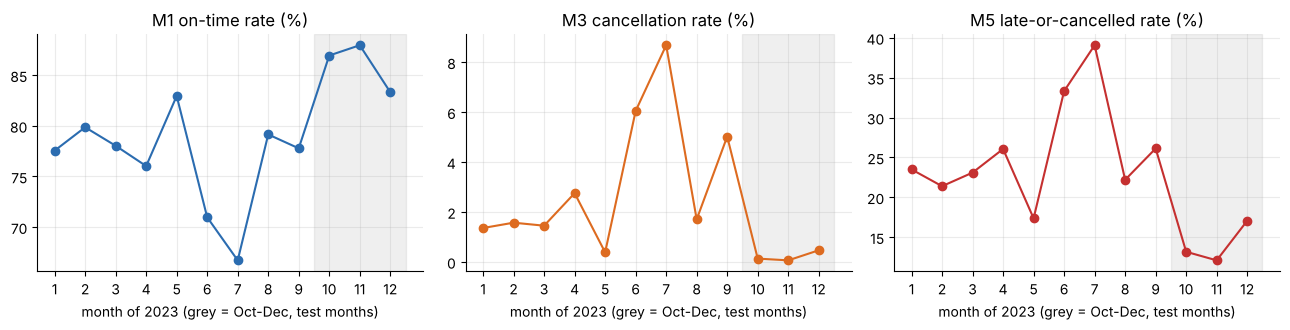

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for a, col, ttl, c in [(ax[0], "M1_on_time_%", "M1 on-time rate (%)", "#2b6cb0"),
                       (ax[1], "M3_cancel_%", "M3 cancellation rate (%)", "#dd6b20"),
                       (ax[2], "M5_late_or_cancelled_%", "M5 late-or-cancelled rate (%)", "#c53030")]:
    a.plot(monthly.index, monthly[col], marker="o", color=c)
    a.axvspan(9.5, 12.5, color="grey", alpha=0.12); a.set_title(ttl); a.set_xlabel("month of 2023 (grey = Oct-Dec, test months)")
    a.set_xticks(range(1, 13))
plt.tight_layout(); plt.show()

## 3. By airline (the "one useful group") and by destination group

Rates come with the number of flights. **Airlines with fewer than 1,000 flights are marked with `*`: do not rank them** (one bad day moves their rate a lot).

In [5]:
air = fl.groupby("carrier").apply(metrics, include_groups=False)
air["flights"] = air.flights.astype(int)
air = air.merge(al, left_index=True, right_on="carrier").set_index("carrier")
air["note"] = np.where(air.flights < 1000, "* under 1,000 flights", "")
air = air.sort_values("M5_late_or_cancelled_%")
display(air[["name", "flights", "M1_on_time_%", "M2_avg_delay_min", "M3_cancel_%", "M4_over_60min_%", "M5_late_or_cancelled_%", "note"]].round(2))

,name,flights,M1_on_time_%,M2_avg_delay_min,M3_cancel_%,M4_over_60min_%,M5_late_or_cancelled_%,note
carrier,,,,,,,,
G4,Allegiant Air,671,90.40,3.98,0.60,3.75,10.13,"* under 1,000 flights"
YX,Republic Airline,88785,87.86,4.21,3.45,4.57,15.17,
9E,Endeavor Air Inc.,54141,84.43,7.44,3.25,5.82,18.31,
AA,American Airlines Inc.,40525,82.26,14.15,1.44,7.66,18.93,
AS,Alaska Airlines Inc.,7843,80.41,12.01,0.88,7.06,20.30,
DL,Delta Air Lines Inc.,61562,79.26,15.10,1.54,7.93,21.96,
OO,SkyWest Airlines Inc.,6432,79.18,19.77,3.39,10.01,23.51,
MQ,Envoy Air,357,75.14,10.46,0.84,5.65,25.49,"* under 1,000 flights"
NK,Spirit Air Lines,15189,74.72,18.15,2.38,10.93,27.07,


Month by month for the 5 airlines with the most flights (M5, late-or-cancelled %, and M3, cancelled %):

In [6]:
top5 = fl.carrier.value_counts().head(5).index.tolist()
sub = fl[fl.carrier.isin(top5)]
m5 = sub.groupby(["month", "carrier"]).apply(lambda d: metrics(d)["M5_late_or_cancelled_%"], include_groups=False).unstack()[top5]
m3 = sub.groupby(["month", "carrier"]).apply(lambda d: metrics(d)["M3_cancel_%"], include_groups=False).unstack()[top5]
print("flights per airline:", fl.carrier.value_counts().head(5).to_dict())
display(pd.concat({"M5 late-or-cancelled %": m5, "M3 cancelled %": m3}, axis=1).round(1))

flights per airline: {'YX': 88785, 'UA': 79641, 'B6': 66169, 'DL': 61562, '9E': 54141}


M5 late-or-cancelled %                         M3 cancelled %                     
carrier                     YX    UA    B6    DL    9E             YX   UA   B6   DL    9E
month                                                                                     
1                         15.8  25.8  25.7  26.3  25.8            1.8  0.7  0.7  0.8   1.9
2                         15.0  24.3  28.4  22.3  16.9            1.8  0.6  1.5  1.3   2.8
3                         13.3  26.5  35.1  26.5  15.6            1.6  0.7  1.4  2.3   1.7
4                         17.4  33.4  35.6  26.6  18.0            3.0  2.9  3.4  3.8   1.2
5                          7.8  26.9  26.0  15.9   9.7            0.1  0.5  0.6  0.6   0.1
6                         25.4  47.7  39.0  30.0  26.1            7.7  8.8  4.5  2.9   8.6
7                         32.6  51.8  51.9  31.6  33.2           14.1  8.3  9.1  3.1  11.3
8                         11.5  24.7  38.2  19.8  19.0            1.7  1.4  2.8  1.3   2.1
9                         22.3  24.5  38.5  25.6  25.8            8.6  3.4  3.6  2.4   8.2
10                         6.5  12.2  25.8  12.5   9.1            0.0  0.1  0.1  0.1   0.0
11                         4.1  11.9  24.0  11.0   8.5            0.0  0.1  0.1  0.0   0.0
12                         8.1  13.3  30.6  16.9  13.9            0.7  0.1  0.3  0.0   1.4

In [7]:
g = fl.merge(gr[["dest", "dest_group", "dest_group_name"]], on="dest", how="left")
by_group = g.groupby("dest_group").apply(metrics, include_groups=False)
by_group["flights"] = by_group.flights.astype(int)
by_group["name"] = g.groupby("dest_group").dest_group_name.first()
print("By destination group (groups built on Jan-Sep in Task 3; metrics here use the whole year):")
display(by_group[["name", "flights", "M1_on_time_%", "M2_avg_delay_min", "M3_cancel_%", "M4_over_60min_%", "M5_late_or_cancelled_%"]].round(2))

By destination group (groups built on Jan-Sep in Task 3; metrics here use the whole year):


,name,flights,M1_on_time_%,M2_avg_delay_min,M3_cancel_%,M4_over_60min_%,M5_late_or_cancelled_%
dest_group,,,,,,,
G1,"Short-haul: mild delays, most cancellations",131450,84.39,7.74,3.31,6.19,18.40
G2,Main long-haul: delays build up through the day,300475,76.97,16.26,2.10,9.25,24.65
G3,Chronic delays on few flights,2982,54.09,35.54,2.55,21.09,47.28
small,Small airports (under 100 flights in Jan-Sep),445,78.05,13.93,0.67,7.24,22.47


## 4. Unusual months

A month is flagged when its **modified z-score** is above 3.5 in absolute value: `0.6745 x (value - median of the 12 months) / MAD`, where MAD is the median absolute deviation from the median. We also list the visibly highest and lowest month of each metric, because with only 12 points the 3.5 rule is strict.

In [8]:
def mod_z(x):
    mad = (x - x.median()).abs().median()
    return 0.6745 * (x - x.median()) / mad
cols = ["M1_on_time_%", "M2_avg_delay_min", "M3_cancel_%", "M4_over_60min_%", "M5_late_or_cancelled_%"]
Z = monthly[cols].apply(mod_z)
display(Z.round(1))
flag = [(c, m, Z.loc[m, c]) for c in cols for m in Z.index if abs(Z.loc[m, c]) > 3.5]
print("flagged by the |z| > 3.5 rule:", [(c, int(m), round(z, 1)) for c, m, z in flag])
ext = pd.DataFrame({"highest": monthly[cols].idxmax(), "lowest": monthly[cols].idxmin()})
print("visibly highest / lowest month for each metric:"); display(ext.T)

,M1_on_time_%,M2_avg_delay_min,M3_cancel_%,M4_over_60min_%,M5_late_or_cancelled_%
month,,,,,
1,-0.2,0.1,-0.1,0.1,0.1
2,0.2,-0.3,0.0,-0.4,-0.2
3,-0.1,-0.0,-0.0,-0.0,0.1
4,-0.5,0.6,0.7,0.5,0.5
5,0.8,-0.7,-0.6,-0.8,-0.8
6,-1.5,1.6,2.6,1.5,1.6
7,-2.3,2.5,4.1,2.3,2.5
8,0.1,0.0,0.1,0.0,-0.1
9,-0.2,0.6,2.0,0.5,0.5


flagged by the |z| > 3.5 rule: [('M3_cancel_%', 7, np.float64(4.1))]
visibly highest / lowest month for each metric:


,M1_on_time_%,M2_avg_delay_min,M3_cancel_%,M4_over_60min_%,M5_late_or_cancelled_%
highest,11,7,7,7,7
lowest,7,11,11,11,11


### Why are those months different? Only evidence counts.

For each month we look at three things:
1. **Weather**: share of weather hours with rain/snow (`precip` > 0), with visibility under 3 miles, and with wind gusts above 25 mph (all three airports; month in New York time).
2. **Bad days**: days when at least 45% of the day's flights were late or cancelled (same rule as Task 2). How many fall in the month, and how much of the month's cancellations and late-or-cancelled flights they hold.
3. **Who**: M5 by origin airport, and the airline that is furthest above its own yearly M5 in that month.

In [9]:
we["month"] = we.time_hour_utc.dt.tz_convert("America/New_York").dt.month
wx = we.groupby("month").agg(rain_hours_pct=("precip", lambda s: 100 * (s > 0).mean()),
                             low_visibility_hours_pct=("visib", lambda s: 100 * (s < 3).mean()),
                             gust_over_25_pct=("wind_gust", lambda s: 100 * (s > 25).mean()))

fl["date"] = fl.sched_dt.dt.tz_localize(None).dt.normalize()
day = fl.groupby("date").agg(n=("late", "size"), rate=("late", "mean"))
bad_dates = day.index[day.rate >= 0.45]
fl["bad_day"] = fl.date.isin(bad_dates)
bd = fl.groupby("month").apply(lambda d: pd.Series({
        "bad_days": d.loc[d.bad_day, "date"].nunique(),
        "share_of_month_cancellations_%": 100 * d.loc[d.bad_day, "cancelled"].sum() / max(d.cancelled.sum(), 1),
        "share_of_month_late_or_cancelled_%": 100 * d.loc[d.bad_day, "late"].sum() / d.late.sum()}), include_groups=False)
origin = fl.groupby(["month", "origin"]).late.mean().unstack().mul(100).add_prefix("M5 ")
yearly_air = fl.groupby("carrier").late.mean()
big = fl.carrier.value_counts()[lambda s: s >= 5000].index
mc = fl[fl.carrier.isin(big)].groupby(["month", "carrier"]).late.mean().unstack()
worst_air = (mc - yearly_air[big]).mul(100).apply(lambda r: f"{r.idxmax()} ({r.max():+.0f} pts)", axis=1).rename("airline furthest above its yearly M5")
evidence = pd.concat([monthly[["M5_late_or_cancelled_%", "M3_cancel_%"]], wx, bd, origin, worst_air], axis=1)
print(f"{len(bad_dates)} bad days in the year")
display(evidence.round(1))

27 bad days in the year


,M5_late_or_cancelled_%,M3_cancel_%,rain_hours_pct,low_visibility_hours_pct,gust_over_25_pct,bad_days,share_of_month_cancellations_%,share_of_month_late_or_cancelled_%,M5 EWR,M5 JFK,M5 LGA,airline furthest above its yearly M5
month,,,,,,,,,,,,
1,23.5,1.4,18.8,2.3,6.2,1.0,24.1,10.8,24.4,24.3,22.1,OO (+14 pts)
2,21.4,1.6,11.5,1.4,8.5,0.0,0.0,0.0,22.3,21.3,20.8,AA (+2 pts)
3,23.1,1.5,18.7,3.5,9.9,2.0,47.5,14.5,24.3,25.8,19.9,NK (+6 pts)
4,26.1,2.8,15.5,10.0,2.3,4.0,39.7,25.2,30.4,27.6,21.0,NK (+8 pts)
5,17.4,0.4,6.9,1.1,0.8,0.0,0.0,0.0,21.8,18.6,12.6,UA (-0 pts)
6,33.3,6.0,8.6,2.5,0.3,6.0,76.2,36.6,41.8,29.1,29.7,UA (+21 pts)
7,39.1,8.7,8.8,0.8,0.2,9.0,68.6,42.3,46.2,38.9,33.0,UA (+25 pts)
8,22.2,1.7,10.0,0.5,0.3,0.0,0.0,0.0,22.0,25.1,20.1,B6 (+5 pts)
9,26.1,5.0,21.4,2.1,0.7,5.0,80.2,38.0,24.5,28.6,25.5,9E (+8 pts)


**Reading the evidence** (all numbers from the table above):
- **June and July** (M5 33% and 39%, cancellations 6.1% and 8.7%) are not wetter, foggier or windier than the other months: both have fewer rain hours than the yearly pattern, and almost no low visibility or strong gusts. What stands out is the **bad days**: June has 6 and July has 9, and they hold 76% and 69% of the months' cancellations and 37% and 42% of the late-or-cancelled flights. September (5 bad days, 80% of its cancellations) is the same story at a smaller scale. So the high summer figures come from a few very bad days, not from a month of slightly worse weather. The data points to **Newark and United**: in June and July Newark's M5 is 41.8% and 46.2% against 29.1% and 38.9% at JFK, and United is the airline furthest above its own yearly rate (+21 and +25 points). The weather of those particular days is only a partial explanation (Task 2 found rain on 27.6% of bad-day flights against 11.6% on other days, and only 21% of rainy days are bad days). **The cause of those days is not explained by the available data**: the data has no cancellation reason, and no air-traffic-control or crew information.
- **October, November and December** (M5 12-17%, cancellations under 0.5%) are the best months, and their weather is not unusually good (October and December have more rain hours than July). They have no bad day at all, which again points to bad days, not weather, as the main driver.
- Only M3 in July is above the strict 3.5 rule; the other metrics' extremes (June, July, Oct, Nov) are visible on the chart but inside it.
- **Do not read the Oct-Dec improvement as a trend that will continue.** With one year of data we cannot tell a seasonal pattern from a change in the airlines.

## 5. Bonus: forecast the on-time rate for October, November, December

Rule: use **only January to September** to forecast M1 for the three months that follow, then compare with what happened. Four simple forecasts:
- **Mean**: the average of the 9 monthly values.
- **Last month**: September's value.
- **Linear trend**: a straight line through the 9 points, extended.
- **Exponential smoothing**: each month is weighted more than the one before; the smoothing factor (alpha) is chosen on January-September only, by the smallest one-step-ahead error.

Seasonality cannot be estimated from a single year, so no method can know that autumn is calm.

In [10]:
m1 = monthly["M1_on_time_%"]
past, actual = m1.loc[1:9], m1.loc[10:12]
x = np.arange(1, 10)

# exponential smoothing: choose alpha on Jan-Sep only (one-step-ahead squared error)
def ses_level(y, a):
    lvl = y[0]; err = 0.0
    for v in y[1:]:
        err += (v - lvl) ** 2; lvl = a * v + (1 - a) * lvl
    return lvl, err
alphas = np.linspace(0.05, 1, 20)
best_a = min(alphas, key=lambda a: ses_level(past.values, a)[1])
slope, intercept = np.polyfit(x, past.values, 1)
fc = pd.DataFrame({"Mean": [past.mean()] * 3,
                   "Last month": [past.iloc[-1]] * 3,
                   "Linear trend": [intercept + slope * t for t in (10, 11, 12)],
                   f"Exp. smoothing (alpha={best_a:.2f})": [ses_level(past.values, best_a)[0]] * 3}, index=[10, 11, 12])
fc.insert(0, "Actual", actual.values)
display(fc.round(2))

M1_combined = metrics(fl[fl.month.isin(TEST_MONTHS)])["M1_on_time_%"]
res = pd.DataFrame({"MAE over the 3 months (pts)": [(fc[c] - fc.Actual).abs().mean() for c in fc.columns[1:]],
                    "Error on Oct-Dec combined (pts)": [fc[c].mean() - M1_combined for c in fc.columns[1:]]}, index=fc.columns[1:])
print(f"Real M1 for Oct-Dec combined: {M1_combined:.2f}%")
display(res.round(2))
winner = res["MAE over the 3 months (pts)"].idxmin()
print("best by MAE:", winner)

,Actual,Mean,Last month,Linear trend,Exp. smoothing (alpha=0.05)
10,86.95,76.56,77.78,74.15,77.13
11,87.96,76.56,77.78,73.67,77.13
12,83.33,76.56,77.78,73.19,77.13


Real M1 for Oct-Dec combined: 86.13%


,MAE over the 3 months (pts),Error on Oct-Dec combined (pts)
Mean,9.52,-9.57
Last month,8.30,-8.35
Linear trend,12.41,-12.46
Exp. smoothing (alpha=0.05),8.95,-9.00


best by MAE: Last month


**Result, said plainly.** Every forecast misses by 8 to 12 percentage points (MAE), always too low, because all four are built on a spring and summer that were much worse than the autumn. The method that wins (smallest MAE: last month, as printed above) wins only by being the least pessimistic: **nine points are too few to trust any of them**, and none of them can see the seasonal improvement. For planning, the agency should treat the monthly M1 as a quantity that jumps with a few bad days (section 4), not as a smooth trend, and should look at M1 together with M3.

## Summary

- Five metrics, each with a precise formula; all 15 check values from the plan are reproduced by the code.
- Monthly table saved to `data/processed/metrics_monthly.parquet`. Airlines and destination groups tabulated with flight counts; small airlines flagged.
- June and July are the unusual months. Weather does not explain them; bad days do. The reason for those bad days is not in the data.
- The bonus forecast from Jan-Sep fails for Oct-Dec, which is a finding in itself: one year is not enough to forecast seasons.